
# Masters Thesis - Advanced ML Pipeline with Statistical Rigor

### This notebook compares 5 models:
### 1. Gaussian Process Regression (GPR)
### 2. Support Vector Regression (SVR)
### 3. Random Forest (RF)
### 4. Artificial Neural Network (ANN)
### 5. Stacking Ensemble (RF + ANN + Ridge)

## Key improvements:
### - 1. REDESIGN STACKING with GPR + ANN (not RF + ANN)
### - 2. LEARNING CURVES to justify N=89
### - 3. SHAP for feature importance (ANN)
### - 4. MULTI-OUTPUT GPR (predict height, dilution_percent & aspect ratio simultaneously) 

### Now updated to include dilution_percent


## Cell 1: Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time
import warnings
warnings.filterwarnings('ignore')

# Sklearn imports
from sklearn.model_selection import (
    cross_validate, cross_val_predict, GridSearchCV, 
    KFold, train_test_split
)
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_squared_error, r2_score, mean_absolute_error,
    mean_absolute_percentage_error
)

# Set random seed for reproducibility
np.random.seed(42)

# Configure plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")




## Cell 2: Load and Explore Data

In [2]:
# Load your Dataset_
df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")  

print(f"Dataset Shape: {df.shape}")
print(f"Samples: {len(df)}")
print(f"\nAvailable columns:")
print(df.columns.tolist())

print(df.head())# Display first few rows



Dataset Shape: (89, 21)
Samples: 89

Available columns:
['sample_id', 'Power', 'Speed', 'Feed', 'width_um', 'LED_J_per_mm', 'VED_J_per_mm3', 'height_um', 'depth_um', 'angle_deg', 'aspect_ratio', 'dilution_percent', 'porosity_%', 'pore_count', 'pore_area_um2', 'meltpool_area_um2', 'bbox_xyxy', 'speed_mm_per_s', 'meltpool_area_mm2', 'A_height_um2', 'A_depth_um2']
                 sample_id  Power  Speed  Feed  width_um  LED_J_per_mm  \
0   1.0_P1860.0_V1.1_F_2.0   1860    1.1     2    2288.6    101.454545   
1  10.0_P2400.0_V1.5_F_4.5   2400    1.5     4    2480.8     96.000000   
2  11.0_P1620.0_V0.9_F_3.0   1620    0.9     3    2039.2    108.000000   
3  12.0_P2470.0_V1.0_F_7.0   2470    1.0     7    2653.1    148.200000   
4  13.0_P2440.0_V1.4_F_7.5   2440    1.4     7    2497.9    104.571429   

   VED_J_per_mm3  height_um  depth_um  angle_deg  ...  dilution_percent  \
0      85.012065     294.92    476.93     179.92  ...         61.790503   
1      55.487128     488.73    583.10    

## Cell 3: Feature Engineering & Data Preparation

In [3]:


# These are the controllable LMD parameters
feature_cols = ['Power','Speed', 'Feed']
X = df[feature_cols].values

# Physics-informed feature: Linear Energy Density (LED)
# LED = Power / Speed is critical for melt pool dynamics
heat_input = X[:, 0] / (X[:, 1] + 1e-6)  # Avoid division by zero
#X_engineered = np.column_stack([X, heat_input])
X_engineered = X

feature_names = ['Power','Speed', 'Feed']

print(f"\n✓ Input Features: {feature_names}")
print(f"  Feature matrix shape: {X_engineered.shape}")

# Display feature statistics
feat_df = pd.DataFrame(X_engineered, columns=feature_names)
print("\nFeature Statistics:")
print(feat_df.describe().round(2))


# We predict two geometric quality metrics // Adjusted to three geometric qualities to include dilution
target_cols = ['height_um', 'aspect_ratio', 'dilution_percent']

# Extract targets
y_height = df['height_um'].values
y_aspect_ratio = df['aspect_ratio'].values
y_dilution_percent = df['dilution_percent'].values

print(f"\n✓ Target Variables: {target_cols}")
print(f"\nTarget Statistics:")
print(f"  Height (μm):      min={y_height.min():.1f}, max={y_height.max():.1f}, "
      f"mean={y_height.mean():.1f} ± {y_height.std():.1f}")
print(f"  Aspect Ratio:     min={y_aspect_ratio.min():.3f}, max={y_aspect_ratio.max():.3f}, "
      f"mean={y_aspect_ratio.mean():.3f} ± {y_aspect_ratio.std():.3f}")
print(f"  Dilution Percent:     min={y_dilution_percent.min():.3f}, max={y_dilution_percent.max():.3f}, "
      f"mean={y_dilution_percent.mean():.3f} ± {y_dilution_percent.std():.3f}")


# Neural networks and SVR require scaled features
# We also scale targets for better ANN convergence, then back-transform later

scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X_engineered)

scaler_height = StandardScaler()
scaler_aspect = StandardScaler()
scaler_dilution = StandardScaler()

y_height_scaled = scaler_height.fit_transform(y_height.reshape(-1, 1)).ravel()
y_aspect_scaled = scaler_aspect.fit_transform(y_aspect_ratio.reshape(-1, 1)).ravel()
y_dilution_scaled = scaler_dilution.fit_transform(y_dilution_percent.reshape(-1, 1)).ravel()

print(f"\n✓ Feature Standardization Complete")
print(f"  Power: {X[:, 0].mean():.1f} → {X_scaled[:, 0].mean():.3f} (mean)")
print(f"  Power: {X[:, 0].std():.1f} → {X_scaled[:, 0].std():.3f} (std)")



✓ Input Features: ['Power', 'Speed', 'Feed']
  Feature matrix shape: (89, 3)

Feature Statistics:
         Power  Speed   Feed
count    89.00  89.00  89.00
mean   2157.64   1.07   4.66
std     378.84   0.32   2.03
min    1330.00   0.40   1.00
25%    1840.00   0.80   3.00
50%    2170.00   1.10   5.00
75%    2470.00   1.30   6.00
max    2790.00   1.60   9.00

✓ Target Variables: ['height_um', 'aspect_ratio', 'dilution_percent']

Target Statistics:
  Height (μm):      min=214.0, max=2432.2, mean=803.4 ± 426.2
  Aspect Ratio:     min=0.078, max=1.402, mean=0.342 ± 0.215
  Dilution Percent:     min=5.155, max=77.641, mean=43.714 ± 14.181

✓ Feature Standardization Complete
  Power: 2157.6 → -0.000 (mean)
  Power: 376.7 → 1.000 (std)


## Cell 4: Define Models with Hyperparameter Search Spaces

In [4]:


print("\n" + "="*80)
print("[3] Model Definitions & Hyperparameter Grids")
print("="*80)

# We'll use GridSearchCV to find optimal hyperparameters for each model
# This is CRITICAL for fair comparison - using default params would be unfair

# ===========================
# 1. GAUSSIAN PROCESS REGRESSION
# ===========================
# GPR provides uncertainty estimates (confidence intervals)
# Good for small datasets but computationally expensive
gpr_base = GaussianProcessRegressor(
    kernel=C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1.0),
    n_restarts_optimizer=5,
    random_state=42
)

gpr_param_grid = {
    'alpha': [1e-10, 1e-5, 1e-2],  # Regularization
    'kernel': [
        C(1.0) * RBF(1.0),
        C(1.0) * RBF(1.0) + WhiteKernel(noise_level=1.0),
    ]
}

print("\n1. Gaussian Process Regression (GPR)")
print("   - Provides uncertainty quantification")
print("   - Hyperparameters: kernel type, alpha (regularization)")
print("   - Note: O(n³) complexity, slow for large N")

# ===========================
# 2. SUPPORT VECTOR REGRESSION
# ===========================
# SVR is robust to outliers and works well in high dimensions
# Epsilon-insensitive loss function
svr_base = SVR()

svr_param_grid = {
    'C': [0.1, 1.0, 10.0, 100.0],           # Regularization strength
    'epsilon': [0.01, 0.1, 0.2],             # Tube width
    'kernel': ['rbf'],                        # Radial basis function
    'gamma': ['scale', 'auto']                # Kernel coefficient
}

print("\n2. Support Vector Regression (SVR)")
print("   - Robust to outliers via epsilon-tube")
print("   - Hyperparameters: C (regularization), epsilon, gamma")

# ===========================
# 3. RANDOM FOREST
# ===========================
# Ensemble of decision trees, naturally handles interactions
# No need to scale features
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_param_grid = {
    'n_estimators': [100, 200, 300],         # Number of trees
    'max_depth': [None, 10, 20],             # Tree depth
    'min_samples_leaf': [1, 2, 4],           # Leaf regularization
    'max_features': ['sqrt', 'log2']         # Features per split
}

print("\n3. Random Forest (RF)")
print("   - Ensemble of decision trees")
print("   - Hyperparameters: n_estimators, max_depth, min_samples_leaf")
print("   - Naturally handles feature interactions")

# ===========================
# 4. ARTIFICIAL NEURAL NETWORK
# ===========================
# Multi-layer perceptron, learns complex non-linear patterns
ann_base = MLPRegressor(
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    max_iter=1000,
    random_state=42
)

ann_param_grid = {
    'hidden_layer_sizes': [
        (64, 32),      # 2 layers: 64 → 32
        (128, 64),     # 2 layers: 128 → 64
        (64, 32, 16)   # 3 layers: 64 → 32 → 16
    ],
    'alpha': [0.0001, 0.001, 0.01],          # L2 regularization
    'learning_rate_init': [0.001, 0.01],     # Initial learning rate
    'activation': ['relu', 'tanh']            # Activation function
}

print("\n4. Artificial Neural Network (ANN/MLP)")
print("   - Multi-layer perceptron with backpropagation")
print("   - Hyperparameters: architecture, alpha (L2), learning rate")
print("   - Uses early stopping to prevent overfitting")




[3] Model Definitions & Hyperparameter Grids

1. Gaussian Process Regression (GPR)
   - Provides uncertainty quantification
   - Hyperparameters: kernel type, alpha (regularization)
   - Note: O(n³) complexity, slow for large N

2. Support Vector Regression (SVR)
   - Robust to outliers via epsilon-tube
   - Hyperparameters: C (regularization), epsilon, gamma

3. Random Forest (RF)
   - Ensemble of decision trees
   - Hyperparameters: n_estimators, max_depth, min_samples_leaf
   - Naturally handles feature interactions

4. Artificial Neural Network (ANN/MLP)
   - Multi-layer perceptron with backpropagation
   - Hyperparameters: architecture, alpha (L2), learning rate
   - Uses early stopping to prevent overfitting


## Cell 5: Hyperparameter Tuning Function

In [6]:
print("\n" + "="*80)
print("[4] Hyperparameter Tuning Setup")
print("="*80)

def tune_hyperparameters(model, param_grid, X, y, model_name, cv=5):
    """
    Perform GridSearchCV to find optimal hyperparameters.
    
    Args:
        model: sklearn estimator
        param_grid: dict of hyperparameter ranges
        X: feature matrix
        y: target vector
        model_name: string name for printing
        cv: number of cross-validation folds
    
    Returns:
        best_model: fitted model with optimal hyperparameters
        best_params: dict of best parameters
        cv_score: best cross-validation R² score
    """
    print(f"\n{'─'*70}")
    print(f"Tuning: {model_name}")
    print(f"{'─'*70}")
    print(f"  Search space: {sum([len(v) if isinstance(v, list) else 1 for v in param_grid.values()])} combinations")
    
    start_time = time.time()
    
    # GridSearchCV exhaustively tries all parameter combinations
    # Uses 5-fold CV by default to evaluate each combination
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cv,
        scoring='r2',              # Optimize for R² score
        n_jobs=-1,                  # Use all CPU cores
        verbose=0
    )
    
    grid_search.fit(X, y)
    
    elapsed = time.time() - start_time
    
    print(f"  ✓ Best R² = {grid_search.best_score_:.4f}")
    print(f"  ✓ Best params: {grid_search.best_params_}")
    print(f"  ✓ Time: {elapsed:.2f}s")
    
    return grid_search.best_estimator_, grid_search.best_params_, grid_search.best_score_

print("\n✓ Hyperparameter tuning function ready")
print("  - Uses 5-fold cross-validation")
print("  - Optimizes for R² score")
print("  - Returns best model configuration")




[4] Hyperparameter Tuning Setup

✓ Hyperparameter tuning function ready
  - Uses 5-fold cross-validation
  - Optimizes for R² score
  - Returns best model configuration


## Cell 6: Tune All Models for HEIGHT Prediction

In [7]:

print("\n" + "="*80)
print("[5] TUNING MODELS: HEIGHT PREDICTION")
print("="*80)

# Create a dictionary to store all tuned models
models_height = {}
params_height = {}
cv_scores_height = {}

# Tune GPR
gpr_height, gpr_params_h, gpr_score_h = tune_hyperparameters(
    gpr_base, gpr_param_grid, X_scaled, y_height_scaled, 
    "Gaussian Process Regression (Height)"
)
models_height['GPR'] = gpr_height
params_height['GPR'] = gpr_params_h
cv_scores_height['GPR'] = gpr_score_h

# Tune SVR
svr_height, svr_params_h, svr_score_h = tune_hyperparameters(
    svr_base, svr_param_grid, X_scaled, y_height_scaled,
    "Support Vector Regression (Height)"
)
models_height['SVR'] = svr_height
params_height['SVR'] = svr_params_h
cv_scores_height['SVR'] = svr_score_h

# Tune RF
rf_height, rf_params_h, rf_score_h = tune_hyperparameters(
    rf_base, rf_param_grid, X_scaled, y_height_scaled,
    "Random Forest (Height)"
)
models_height['RF'] = rf_height
params_height['RF'] = rf_params_h
cv_scores_height['RF'] = rf_score_h

# Tune ANN
ann_height, ann_params_h, ann_score_h = tune_hyperparameters(
    ann_base, ann_param_grid, X_scaled, y_height_scaled,
    "Artificial Neural Network (Height)"
)
models_height['ANN'] = ann_height
params_height['ANN'] = ann_params_h
cv_scores_height['ANN'] = ann_score_h

print("\n" + "="*70)
print("HEIGHT TUNING COMPLETE - Summary:")
print("="*70)
for name, score in cv_scores_height.items():
    print(f"  {name:6s}: R² = {score:.4f}")


[5] TUNING MODELS: HEIGHT PREDICTION

──────────────────────────────────────────────────────────────────────
Tuning: Gaussian Process Regression (Height)
──────────────────────────────────────────────────────────────────────
  Search space: 5 combinations


  ✓ Best R² = 0.9395
  ✓ Best params: {'alpha': 0.01, 'kernel': 1**2 * RBF(length_scale=1)}
  ✓ Time: 4.02s

──────────────────────────────────────────────────────────────────────
Tuning: Support Vector Regression (Height)
──────────────────────────────────────────────────────────────────────
  Search space: 10 combinations
  ✓ Best R² = 0.8286
  ✓ Best params: {'C': 10.0, 'epsilon': 0.2, 'gamma': 'auto', 'kernel': 'rbf'}
  ✓ Time: 0.21s

──────────────────────────────────────────────────────────────────────
Tuning: Random Forest (Height)
──────────────────────────────────────────────────────────────────────
  Search space: 11 combinations
  ✓ Best R² = 0.7324
  ✓ Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
  ✓ Time: 17.51s

──────────────────────────────────────────────────────────────────────
Tuning: Artificial Neural Network (Height)
──────────────────────────────────────────────────────────────────────
  Search space: 10 comb

## Cell 7: Build Stacking Ensemble for HEIGHT (with tuned Ridge alpha)

In [8]:
print("\n" + "="*80)
print("[6] Building Stacking Ensemble: HEIGHT")
print("="*80)

# Stacking combines RF and ANN predictions using Ridge regression
# We'll also tune the Ridge alpha parameter

# Create base stacking model
stacking_height_base = StackingRegressor(
    estimators=[
        ('rf', rf_height),    # Use tuned RF
        ('ann', ann_height)   # Use tuned ANN
    ],
    final_estimator=Ridge(),
    cv=5,
    n_jobs=-1
)

# Tune Ridge alpha in the stacking ensemble
ridge_param_grid = {
    'final_estimator__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

stacking_height, stack_params_h, stack_score_h = tune_hyperparameters(
    stacking_height_base, ridge_param_grid, X_scaled, y_height_scaled,
    "Stacking Ensemble (RF + ANN + Ridge) - Height"
)

models_height['Stacking'] = stacking_height
params_height['Stacking'] = stack_params_h
cv_scores_height['Stacking'] = stack_score_h

print("\n✓ Stacking Ensemble for Height Complete")
print(f"  Optimal Ridge alpha = {stack_params_h['final_estimator__alpha']}")


[6] Building Stacking Ensemble: HEIGHT

──────────────────────────────────────────────────────────────────────
Tuning: Stacking Ensemble (RF + ANN + Ridge) - Height
──────────────────────────────────────────────────────────────────────
  Search space: 5 combinations
  ✓ Best R² = 0.8986
  ✓ Best params: {'final_estimator__alpha': 0.01}
  ✓ Time: 17.12s

✓ Stacking Ensemble for Height Complete
  Optimal Ridge alpha = 0.01


## Cell 8: Tune All Models for ASPECT RATIO Prediction

In [9]:
print("\n" + "="*80)
print("[7] TUNING MODELS: ASPECT RATIO PREDICTION")
print("="*80)

# Repeat the process for aspect ratio
models_aspect = {}
params_aspect = {}
cv_scores_aspect = {}

# Tune GPR
gpr_aspect, gpr_params_a, gpr_score_a = tune_hyperparameters(
    gpr_base, gpr_param_grid, X_scaled, y_aspect_scaled,
    "Gaussian Process Regression (Aspect Ratio)"
)
models_aspect['GPR'] = gpr_aspect
params_aspect['GPR'] = gpr_params_a
cv_scores_aspect['GPR'] = gpr_score_a

# Tune SVR
svr_aspect, svr_params_a, svr_score_a = tune_hyperparameters(
    svr_base, svr_param_grid, X_scaled, y_aspect_scaled,
    "Support Vector Regression (Aspect Ratio)"
)
models_aspect['SVR'] = svr_aspect
params_aspect['SVR'] = svr_params_a
cv_scores_aspect['SVR'] = svr_score_a

# Tune RF
rf_aspect, rf_params_a, rf_score_a = tune_hyperparameters(
    rf_base, rf_param_grid, X_scaled, y_aspect_scaled,
    "Random Forest (Aspect Ratio)"
)
models_aspect['RF'] = rf_aspect
params_aspect['RF'] = rf_params_a
cv_scores_aspect['RF'] = rf_score_a

# Tune ANN
ann_aspect, ann_params_a, ann_score_a = tune_hyperparameters(
    ann_base, ann_param_grid, X_scaled, y_aspect_scaled,
    "Artificial Neural Network (Aspect Ratio)"
)
models_aspect['ANN'] = ann_aspect
params_aspect['ANN'] = ann_params_a
cv_scores_aspect['ANN'] = ann_score_a

print("\n" + "="*70)
print("ASPECT RATIO TUNING COMPLETE - Summary:")
print("="*70)
for name, score in cv_scores_aspect.items():
    print(f"  {name:6s}: R² = {score:.4f}")


[7] TUNING MODELS: ASPECT RATIO PREDICTION

──────────────────────────────────────────────────────────────────────
Tuning: Gaussian Process Regression (Aspect Ratio)
──────────────────────────────────────────────────────────────────────
  Search space: 5 combinations
  ✓ Best R² = 0.9089
  ✓ Best params: {'alpha': 0.01, 'kernel': 1**2 * RBF(length_scale=1)}
  ✓ Time: 1.11s

──────────────────────────────────────────────────────────────────────
Tuning: Support Vector Regression (Aspect Ratio)
──────────────────────────────────────────────────────────────────────
  Search space: 10 combinations
  ✓ Best R² = 0.7899
  ✓ Best params: {'C': 10.0, 'epsilon': 0.1, 'gamma': 'auto', 'kernel': 'rbf'}
  ✓ Time: 0.17s

──────────────────────────────────────────────────────────────────────
Tuning: Random Forest (Aspect Ratio)
──────────────────────────────────────────────────────────────────────
  Search space: 11 combinations
  ✓ Best R² = 0.6973
  ✓ Best params: {'max_depth': None, 'max_features

## Cell 9: Build Stacking Ensemble for ASPECT RATIO

In [9]:
print("\n" + "="*80)
print("[8] Building Stacking Ensemble: ASPECT RATIO")
print("="*80)

stacking_aspect_base = StackingRegressor(
    estimators=[
        ('rf', rf_aspect),
        ('ann', ann_aspect)
    ],
    final_estimator=Ridge(),
    cv=5,
    n_jobs=-1
)

stacking_aspect, stack_params_a, stack_score_a = tune_hyperparameters(
    stacking_aspect_base, ridge_param_grid, X_scaled, y_aspect_scaled,
    "Stacking Ensemble (RF + ANN + Ridge) - Aspect Ratio"
)

models_aspect['Stacking'] = stacking_aspect
params_aspect['Stacking'] = stack_params_a
cv_scores_aspect['Stacking'] = stack_score_a

print("\n✓ Stacking Ensemble for Aspect Ratio Complete")
print(f"  Optimal Ridge alpha = {stack_params_a['final_estimator__alpha']}")




[8] Building Stacking Ensemble: ASPECT RATIO

──────────────────────────────────────────────────────────────────────
Tuning: Stacking Ensemble (RF + ANN + Ridge) - Aspect Ratio
──────────────────────────────────────────────────────────────────────
  Search space: 5 combinations
  ✓ Best R² = 0.8155
  ✓ Best params: {'final_estimator__alpha': 10.0}
  ✓ Time: 19.31s

✓ Stacking Ensemble for Aspect Ratio Complete
  Optimal Ridge alpha = 10.0


## Cell 10: Comprehensive Model Evaluation Function

In [10]:
print("\n" + "="*80)
print("[9] Comprehensive Evaluation Pipeline")
print("="*80)

def evaluate_model_comprehensive(model, X, y, y_scaler, model_name, cv=5):
    """
    Comprehensive model evaluation with:
    - Cross-validation metrics
    - Back-transformed predictions (original units)
    - Statistical significance testing
    - Prediction intervals
    
    Args:
        model: fitted sklearn model
        X: feature matrix (scaled)
        y: target vector (scaled)
        y_scaler: StandardScaler for back-transformation
        model_name: string name
        cv: number of folds
    
    Returns:
        dict with all evaluation metrics
    """
    # ═══════════════════════════════════════════════════════════
    # 1. CROSS-VALIDATION METRICS (Scaled Space)
    # ═══════════════════════════════════════════════════════════
    scoring = ['r2', 'neg_mean_squared_error', 'neg_mean_absolute_error']
    cv_results = cross_validate(
        model, X, y, cv=cv, scoring=scoring, n_jobs=-1
    )
    
    r2_mean = cv_results['test_r2'].mean()
    r2_std = cv_results['test_r2'].std()
    rmse_mean = np.sqrt(-cv_results['test_neg_mean_squared_error'].mean())
    rmse_std = np.sqrt(cv_results['test_neg_mean_squared_error'].std())
    mae_mean = -cv_results['test_neg_mean_absolute_error'].mean()
    mae_std = cv_results['test_neg_mean_absolute_error'].std()
    
    # ═══════════════════════════════════════════════════════════
    # 2. GET OUT-OF-FOLD PREDICTIONS for back-transformation
    # ═══════════════════════════════════════════════════════════
    y_pred_scaled = cross_val_predict(model, X, y, cv=cv)
    
    # Back-transform to original units
    y_original = y_scaler.inverse_transform(y.reshape(-1, 1)).ravel()
    y_pred_original = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    
    # ═══════════════════════════════════════════════════════════
    # 3. METRICS IN ORIGINAL UNITS (for interpretability)
    # ═══════════════════════════════════════════════════════════
    r2_original = r2_score(y_original, y_pred_original)
    rmse_original = np.sqrt(mean_squared_error(y_original, y_pred_original))
    mae_original = mean_absolute_error(y_original, y_pred_original)
    mape_original = mean_absolute_percentage_error(y_original, y_pred_original) * 100  # as %
    
    # ═══════════════════════════════════════════════════════════
    # 4. RESIDUAL ANALYSIS
    # ═══════════════════════════════════════════════════════════
    residuals = y_original - y_pred_original
    residuals_normalized = (residuals - residuals.mean()) / residuals.std()
    
    # Normality test (Shapiro-Wilk)
    # H0: residuals are normally distributed
    # If p < 0.05, reject H0 (not normal)
    _, normality_pvalue = stats.shapiro(residuals_normalized)
    
    # ═══════════════════════════════════════════════════════════
    # 5. COMPILE RESULTS
    # ═══════════════════════════════════════════════════════════
    results = {
        # Scaled metrics
        'r2_scaled': r2_mean,
        'r2_scaled_std': r2_std,
        'rmse_scaled': rmse_mean,
        'rmse_scaled_std': rmse_std,
        'mae_scaled': mae_mean,
        'mae_scaled_std': mae_std,
        
        # Original unit metrics
        'r2_original': r2_original,
        'rmse_original': rmse_original,
        'mae_original': mae_original,
        'mape_original': mape_original,
        
        # Predictions and residuals
        'y_true': y_original,
        'y_pred': y_pred_original,
        'residuals': residuals,
        'normality_pvalue': normality_pvalue
    }
    
    return results

print("✓ Comprehensive evaluation function ready")
print("  - Cross-validation metrics (R², RMSE, MAE)")
print("  - Back-transformed predictions (original units)")
print("  - Residual analysis (normality test)")




[9] Comprehensive Evaluation Pipeline
✓ Comprehensive evaluation function ready
  - Cross-validation metrics (R², RMSE, MAE)
  - Back-transformed predictions (original units)
  - Residual analysis (normality test)


In [11]:


# ============================================================================
## Cell 11: Evaluate All Models - HEIGHT
# ============================================================================
print("\n" + "="*80)
print("[10] EVALUATING ALL MODELS: HEIGHT PREDICTION")
print("="*80)

results_height = {}

for name, model in models_height.items():
    print(f"\n{'─'*70}")
    print(f"Evaluating: {name} (Height)")
    print(f"{'─'*70}")
    
    start_time = time.time()
    results = evaluate_model_comprehensive(
        model, X_scaled, y_height_scaled, scaler_height, name
    )
    elapsed = time.time() - start_time
    
    results['eval_time'] = elapsed
    results_height[name] = results
    
    # Print summary
    print(f"  R² (original units): {results['r2_original']:.4f}")
    print(f"  RMSE: {results['rmse_original']:.2f} μm")
    print(f"  MAE: {results['mae_original']:.2f} μm")
    print(f"  MAPE: {results['mape_original']:.2f}%")
    print(f"  Residuals normality (p-value): {results['normality_pvalue']:.4f}")
    print(f"  Evaluation time: {elapsed:.2f}s")

print("\n" + "="*80)
print("HEIGHT EVALUATION COMPLETE")
print("="*80)




[10] EVALUATING ALL MODELS: HEIGHT PREDICTION

──────────────────────────────────────────────────────────────────────
Evaluating: GPR (Height)
──────────────────────────────────────────────────────────────────────
  R² (original units): 0.9434
  RMSE: 101.39 μm
  MAE: 70.00 μm
  MAPE: 9.94%
  Residuals normality (p-value): 0.0000
  Evaluation time: 0.79s

──────────────────────────────────────────────────────────────────────
Evaluating: SVR (Height)
──────────────────────────────────────────────────────────────────────
  R² (original units): 0.7396
  RMSE: 217.48 μm
  MAE: 111.18 μm
  MAPE: 15.47%
  Residuals normality (p-value): 0.0000
  Evaluation time: 0.02s

──────────────────────────────────────────────────────────────────────
Evaluating: RF (Height)
──────────────────────────────────────────────────────────────────────
  R² (original units): 0.6291
  RMSE: 259.56 μm
  MAE: 139.79 μm
  MAPE: 19.19%
  Residuals normality (p-value): 0.0000
  Evaluation time: 2.36s

────────────────

## Cell 12: Evaluate All Models - ASPECT RATIO

In [12]:
print("\n" + "="*80)
print("[11] EVALUATING ALL MODELS: ASPECT RATIO PREDICTION")
print("="*80)

results_aspect = {}

for name, model in models_aspect.items():
    print(f"\n{'─'*70}")
    print(f"Evaluating: {name} (Aspect Ratio)")
    print(f"{'─'*70}")
    
    start_time = time.time()
    results = evaluate_model_comprehensive(
        model, X_scaled, y_aspect_scaled, scaler_aspect, name
    )
    elapsed = time.time() - start_time
    
    results['eval_time'] = elapsed
    results_aspect[name] = results
    
    # Print summary
    print(f"  R² (original units): {results['r2_original']:.4f}")
    print(f"  RMSE: {results['rmse_original']:.4f}")
    print(f"  MAE: {results['mae_original']:.4f}")
    print(f"  MAPE: {results['mape_original']:.2f}%")
    print(f"  Residuals normality (p-value): {results['normality_pvalue']:.4f}")
    print(f"  Evaluation time: {elapsed:.2f}s")

print("\n" + "="*80)
print("ASPECT RATIO EVALUATION COMPLETE")
print("="*80)




[11] EVALUATING ALL MODELS: ASPECT RATIO PREDICTION

──────────────────────────────────────────────────────────────────────
Evaluating: GPR (Aspect Ratio)
──────────────────────────────────────────────────────────────────────
  R² (original units): 0.8676
  RMSE: 0.0784
  MAE: 0.0381
  MAPE: 10.84%
  Residuals normality (p-value): 0.0000
  Evaluation time: 0.80s

──────────────────────────────────────────────────────────────────────
Evaluating: SVR (Aspect Ratio)
──────────────────────────────────────────────────────────────────────
  R² (original units): 0.6085
  RMSE: 0.1347
  MAE: 0.0558
  MAPE: 15.38%
  Residuals normality (p-value): 0.0000
  Evaluation time: 0.03s

──────────────────────────────────────────────────────────────────────
Evaluating: RF (Aspect Ratio)
──────────────────────────────────────────────────────────────────────
  R² (original units): 0.5058
  RMSE: 0.1514
  MAE: 0.0641
  MAPE: 18.99%
  Residuals normality (p-value): 0.0000
  Evaluation time: 2.32s

────────

## Cell 13: Statistical Significance Testing

In [13]:
print("\n" + "="*80)
print("[12] STATISTICAL SIGNIFICANCE TESTING")
print("="*80)

def pairwise_significance_test(results_dict, metric='mae_original'):
    """
    Perform pairwise statistical significance tests between models.
    Uses Wilcoxon signed-rank test (non-parametric paired test).
    
    Args:
        results_dict: dict of model results
        metric: which metric to compare (uses absolute errors)
    
    Returns:
        DataFrame with p-values for all pairs
    """
    models = list(results_dict.keys())
    n_models = len(models)
    
    # Create p-value matrix
    p_values = np.ones((n_models, n_models))
    
    for i, model1 in enumerate(models):
        for j, model2 in enumerate(models):
            if i < j:  # Only compute upper triangle
                # Get absolute errors for both models
                errors1 = np.abs(results_dict[model1]['residuals'])
                errors2 = np.abs(results_dict[model2]['residuals'])
                
                # Wilcoxon signed-rank test
                # H0: errors from both models have same distribution
                # If p < 0.05, models are significantly different
                try:
                    _, p_val = stats.wilcoxon(errors1, errors2, alternative='two-sided')
                    p_values[i, j] = p_val
                    p_values[j, i] = p_val
                except:
                    p_values[i, j] = np.nan
                    p_values[j, i] = np.nan
    
    # Convert to DataFrame
    p_df = pd.DataFrame(p_values, index=models, columns=models)
    
    return p_df

# ──────────────────────────────────────────────────────────────
# HEIGHT SIGNIFICANCE TESTS
# ──────────────────────────────────────────────────────────────
print("\n" + "─"*70)
print("HEIGHT: Pairwise Significance Tests (Wilcoxon)")
print("─"*70)
print("p < 0.05 means models are significantly different\n")

p_values_height = pairwise_significance_test(results_height)
print(p_values_height.round(4))

# Find best model for HEIGHT
best_height_model = min(results_height.keys(), 
                        key=lambda k: results_height[k]['mae_original'])
print(f"\n✓ Best HEIGHT model: {best_height_model}")
print(f"  MAE = {results_height[best_height_model]['mae_original']:.2f} μm")

# ──────────────────────────────────────────────────────────────
# ASPECT RATIO SIGNIFICANCE TESTS
# ──────────────────────────────────────────────────────────────
print("\n" + "─"*70)
print("ASPECT RATIO: Pairwise Significance Tests (Wilcoxon)")
print("─"*70)
print("p < 0.05 means models are significantly different\n")

p_values_aspect = pairwise_significance_test(results_aspect)
print(p_values_aspect.round(4))

# Find best model for ASPECT RATIO
best_aspect_model = min(results_aspect.keys(),
                        key=lambda k: results_aspect[k]['mae_original'])
print(f"\n✓ Best ASPECT RATIO model: {best_aspect_model}")
print(f"  MAE = {results_aspect[best_aspect_model]['mae_original']:.4f}")




[12] STATISTICAL SIGNIFICANCE TESTING

──────────────────────────────────────────────────────────────────────
HEIGHT: Pairwise Significance Tests (Wilcoxon)
──────────────────────────────────────────────────────────────────────
p < 0.05 means models are significantly different

             GPR     SVR      RF     ANN  Stacking
GPR       1.0000  0.0004  0.0000  0.0124    0.0270
SVR       0.0004  1.0000  0.0018  0.0722    0.1611
RF        0.0000  0.0018  1.0000  0.0005    0.0037
ANN       0.0124  0.0722  0.0005  1.0000    0.3670
Stacking  0.0270  0.1611  0.0037  0.3670    1.0000

✓ Best HEIGHT model: GPR
  MAE = 70.00 μm

──────────────────────────────────────────────────────────────────────
ASPECT RATIO: Pairwise Significance Tests (Wilcoxon)
──────────────────────────────────────────────────────────────────────
p < 0.05 means models are significantly different

             GPR     SVR      RF     ANN  Stacking
GPR       1.0000  0.0003  0.0033  0.4454    0.0353
SVR       0.0003  1.00

## Cell 14: Create Performance Summary Tables

In [14]:
print("\n" + "="*80)
print("[13] PERFORMANCE SUMMARY TABLES")
print("="*80)

# ──────────────────────────────────────────────────────────────
# HEIGHT SUMMARY TABLE
# ──────────────────────────────────────────────────────────────
height_summary = pd.DataFrame({
    'Model': results_height.keys(),
    'R²': [r['r2_original'] for r in results_height.values()],
    'RMSE (μm)': [r['rmse_original'] for r in results_height.values()],
    'MAE (μm)': [r['mae_original'] for r in results_height.values()],
    'MAPE (%)': [r['mape_original'] for r in results_height.values()],
    'Eval Time (s)': [r['eval_time'] for r in results_height.values()]
})

# Sort by MAE
height_summary = height_summary.sort_values('MAE (μm)')
height_summary = height_summary.reset_index(drop=True)
height_summary.index = height_summary.index + 1  # Ranking

print("\n" + "─"*70)
print("HEIGHT PREDICTION - Performance Ranking")
print("─"*70)
print(height_summary.to_string(index=True))

# ──────────────────────────────────────────────────────────────
# ASPECT RATIO SUMMARY TABLE
# ──────────────────────────────────────────────────────────────
aspect_summary = pd.DataFrame({
    'Model': results_aspect.keys(),
    'R²': [r['r2_original'] for r in results_aspect.values()],
    'RMSE': [r['rmse_original'] for r in results_aspect.values()],
    'MAE': [r['mae_original'] for r in results_aspect.values()],
    'MAPE (%)': [r['mape_original'] for r in results_aspect.values()],
    'Eval Time (s)': [r['eval_time'] for r in results_aspect.values()]
})

aspect_summary = aspect_summary.sort_values('MAE')
aspect_summary = aspect_summary.reset_index(drop=True)
aspect_summary.index = aspect_summary.index + 1

print("\n" + "─"*70)
print("ASPECT RATIO PREDICTION - Performance Ranking")
print("─"*70)
print(aspect_summary.to_string(index=True))

# Save to CSV for thesis
height_summary.to_csv('height_model_comparison.csv', index=False)
aspect_summary.to_csv('aspect_ratio_model_comparison.csv', index=False)
print("\n✓ Summary tables saved to CSV")




[13] PERFORMANCE SUMMARY TABLES

──────────────────────────────────────────────────────────────────────
HEIGHT PREDICTION - Performance Ranking
──────────────────────────────────────────────────────────────────────
      Model        R²   RMSE (μm)    MAE (μm)   MAPE (%)  Eval Time (s)
1       GPR  0.943406  101.393821   70.004772   9.942895       0.785123
2       ANN  0.930052  112.723710   77.909035  10.422781       0.669787
3  Stacking  0.917210  122.635672   83.191946  11.255801      13.525321
4       SVR  0.739627  217.482604  111.176503  15.469372       0.018717
5        RF  0.629124  259.561932  139.793269  19.185255       2.357097

──────────────────────────────────────────────────────────────────────
ASPECT RATIO PREDICTION - Performance Ranking
──────────────────────────────────────────────────────────────────────
      Model        R²      RMSE       MAE   MAPE (%)  Eval Time (s)
1       GPR  0.867596  0.078354  0.038089  10.842827       0.795810
2       ANN  0.885606  0.07

## Cell 15: Visualization 1 - Performance Comparison Bar Charts



[14] VISUALIZATION: Performance Comparison


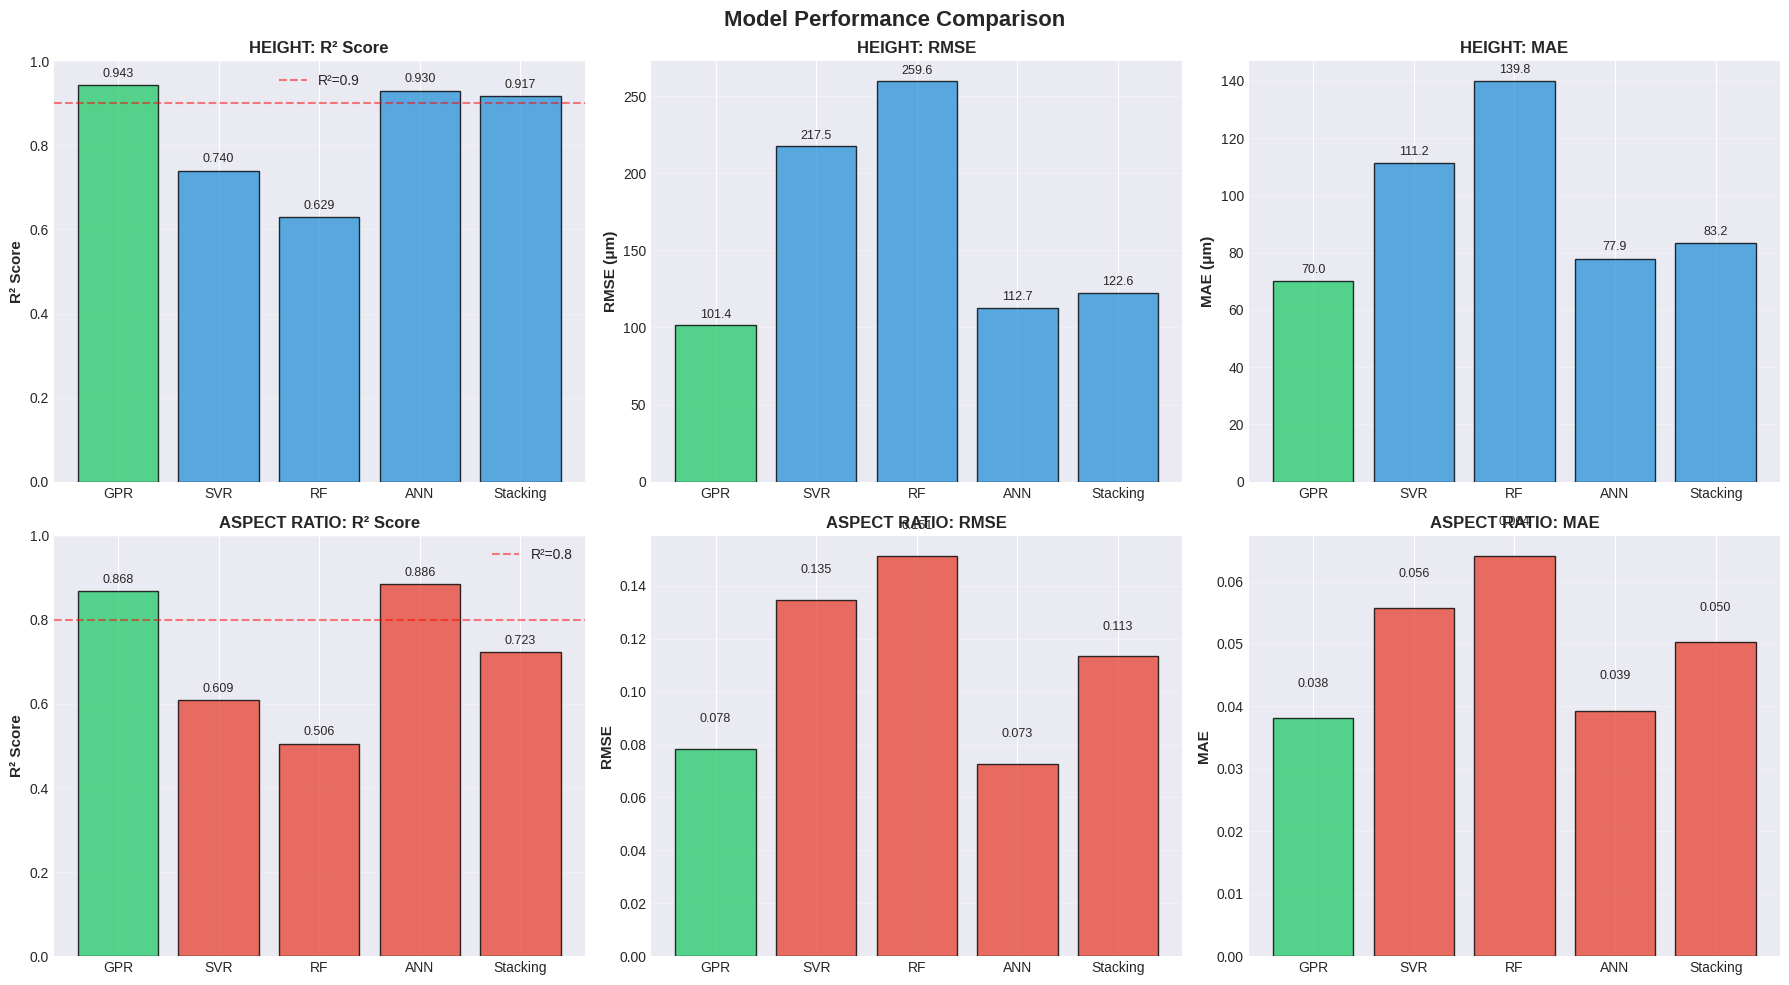


✓ Performance comparison chart saved: model_comparison_metrics.png


In [15]:
print("\n" + "="*80)
print("[14] VISUALIZATION: Performance Comparison")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

models_list = list(results_height.keys())

# ──────────────────────────────────────────────────────────────
# HEIGHT METRICS
# ──────────────────────────────────────────────────────────────
# R² Score
ax = axes[0, 0]
r2_vals = [results_height[m]['r2_original'] for m in models_list]
colors = ['#2ecc71' if m == best_height_model else '#3498db' for m in models_list]
ax.bar(models_list, r2_vals, color=colors, alpha=0.8, edgecolor='black')
ax.set_ylabel('R² Score', fontsize=11, fontweight='bold')
ax.set_title('HEIGHT: R² Score', fontsize=12, fontweight='bold')
ax.set_ylim([0, 1])
ax.axhline(y=0.9, color='red', linestyle='--', alpha=0.5, label='R²=0.9')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(r2_vals):
    ax.text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

# RMSE
ax = axes[0, 1]
rmse_vals = [results_height[m]['rmse_original'] for m in models_list]
ax.bar(models_list, rmse_vals, color=colors, alpha=0.8, edgecolor='black')
ax.set_ylabel('RMSE (μm)', fontsize=11, fontweight='bold')
ax.set_title('HEIGHT: RMSE', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(rmse_vals):
    ax.text(i, v + 5, f'{v:.1f}', ha='center', fontsize=9)

# MAE
ax = axes[0, 2]
mae_vals = [results_height[m]['mae_original'] for m in models_list]
ax.bar(models_list, mae_vals, color=colors, alpha=0.8, edgecolor='black')
ax.set_ylabel('MAE (μm)', fontsize=11, fontweight='bold')
ax.set_title('HEIGHT: MAE', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(mae_vals):
    ax.text(i, v + 3, f'{v:.1f}', ha='center', fontsize=9)

# ──────────────────────────────────────────────────────────────
# ASPECT RATIO METRICS
# ──────────────────────────────────────────────────────────────
colors_aspect = ['#2ecc71' if m == best_aspect_model else '#e74c3c' for m in models_list]

# R² Score
ax = axes[1, 0]
r2_vals_a = [results_aspect[m]['r2_original'] for m in models_list]
ax.bar(models_list, r2_vals_a, color=colors_aspect, alpha=0.8, edgecolor='black')
ax.set_ylabel('R² Score', fontsize=11, fontweight='bold')
ax.set_title('ASPECT RATIO: R² Score', fontsize=12, fontweight='bold')
ax.set_ylim([0, 1])
ax.axhline(y=0.8, color='red', linestyle='--', alpha=0.5, label='R²=0.8')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(r2_vals_a):
    ax.text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)

# RMSE
ax = axes[1, 1]
rmse_vals_a = [results_aspect[m]['rmse_original'] for m in models_list]
ax.bar(models_list, rmse_vals_a, color=colors_aspect, alpha=0.8, edgecolor='black')
ax.set_ylabel('RMSE', fontsize=11, fontweight='bold')
ax.set_title('ASPECT RATIO: RMSE', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(rmse_vals_a):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)

# MAE
ax = axes[1, 2]
mae_vals_a = [results_aspect[m]['mae_original'] for m in models_list]
ax.bar(models_list, mae_vals_a, color=colors_aspect, alpha=0.8, edgecolor='black')
ax.set_ylabel('MAE', fontsize=11, fontweight='bold')
ax.set_title('ASPECT RATIO: MAE', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(mae_vals_a):
    ax.text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('model_comparison_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Performance comparison chart saved: model_comparison_metrics.png")



## Cell 16: Visualization 2 - Predictions vs Actual (Best Models)


[15] VISUALIZATION: Predictions vs Actual


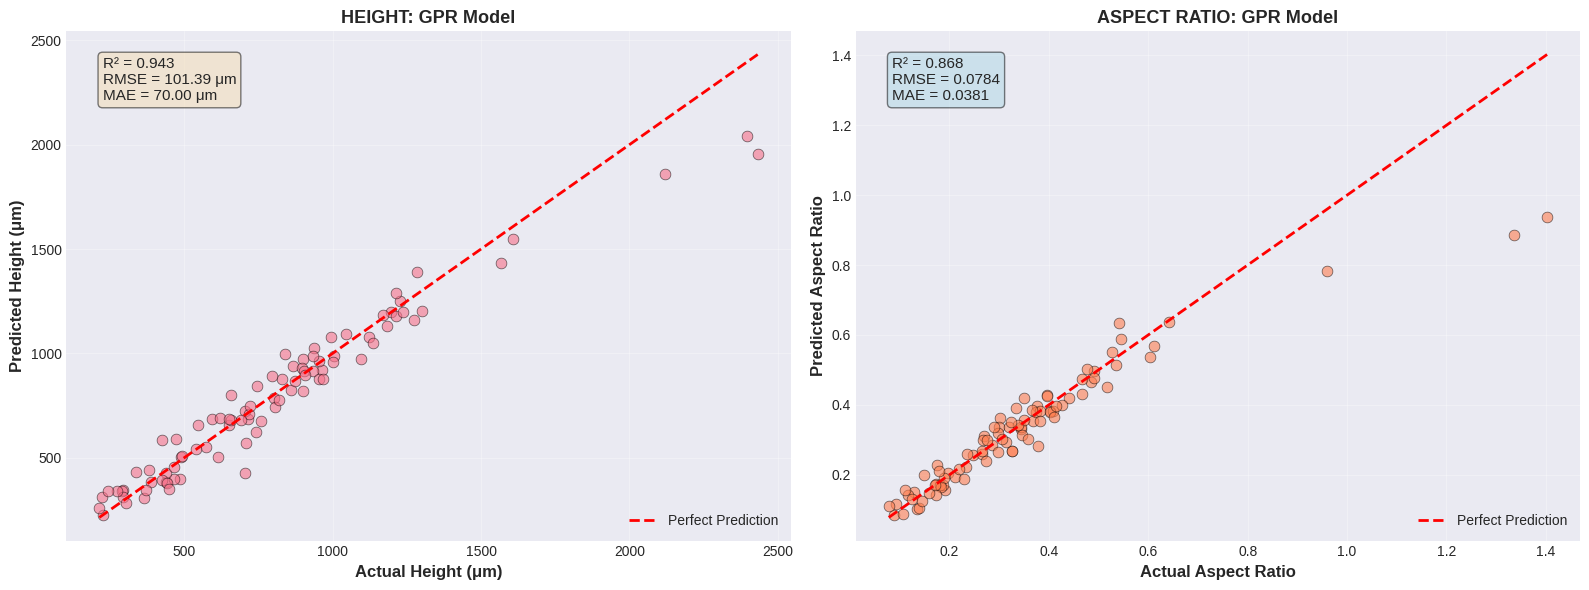


✓ Predictions vs Actual plot saved: predictions_vs_actual.png


In [16]:
print("\n" + "="*80)
print("[15] VISUALIZATION: Predictions vs Actual")
print("="*80)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ──────────────────────────────────────────────────────────────
# HEIGHT: Best Model Predictions
# ──────────────────────────────────────────────────────────────
ax = axes[0]
best_h_results = results_height[best_height_model]
y_true_h = best_h_results['y_true']
y_pred_h = best_h_results['y_pred']

# Scatter plot
ax.scatter(y_true_h, y_pred_h, alpha=0.6, s=60, edgecolors='black', linewidths=0.5)

# Perfect prediction line
min_val = min(y_true_h.min(), y_pred_h.min())
max_val = max(y_true_h.max(), y_pred_h.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

# Add metrics text
r2 = best_h_results['r2_original']
rmse = best_h_results['rmse_original']
mae = best_h_results['mae_original']
text_str = f"R² = {r2:.3f}\nRMSE = {rmse:.2f} μm\nMAE = {mae:.2f} μm"
ax.text(0.05, 0.95, text_str, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.set_xlabel('Actual Height (μm)', fontsize=12, fontweight='bold')
ax.set_ylabel('Predicted Height (μm)', fontsize=12, fontweight='bold')
ax.set_title(f'HEIGHT: {best_height_model} Model', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

# ──────────────────────────────────────────────────────────────
# ASPECT RATIO: Best Model Predictions
# ──────────────────────────────────────────────────────────────
ax = axes[1]
best_a_results = results_aspect[best_aspect_model]
y_true_a = best_a_results['y_true']
y_pred_a = best_a_results['y_pred']

ax.scatter(y_true_a, y_pred_a, alpha=0.6, s=60, color='coral', 
           edgecolors='black', linewidths=0.5)

min_val = min(y_true_a.min(), y_pred_a.min())
max_val = max(y_true_a.max(), y_pred_a.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

r2 = best_a_results['r2_original']
rmse = best_a_results['rmse_original']
mae = best_a_results['mae_original']
text_str = f"R² = {r2:.3f}\nRMSE = {rmse:.4f}\nMAE = {mae:.4f}"
ax.text(0.05, 0.95, text_str, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

ax.set_xlabel('Actual Aspect Ratio', fontsize=12, fontweight='bold')
ax.set_ylabel('Predicted Aspect Ratio', fontsize=12, fontweight='bold')
ax.set_title(f'ASPECT RATIO: {best_aspect_model} Model', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('predictions_vs_actual.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Predictions vs Actual plot saved: predictions_vs_actual.png")



## Cell 17: Visualization 3 - Residual Analysis


[16] VISUALIZATION: Residual Analysis


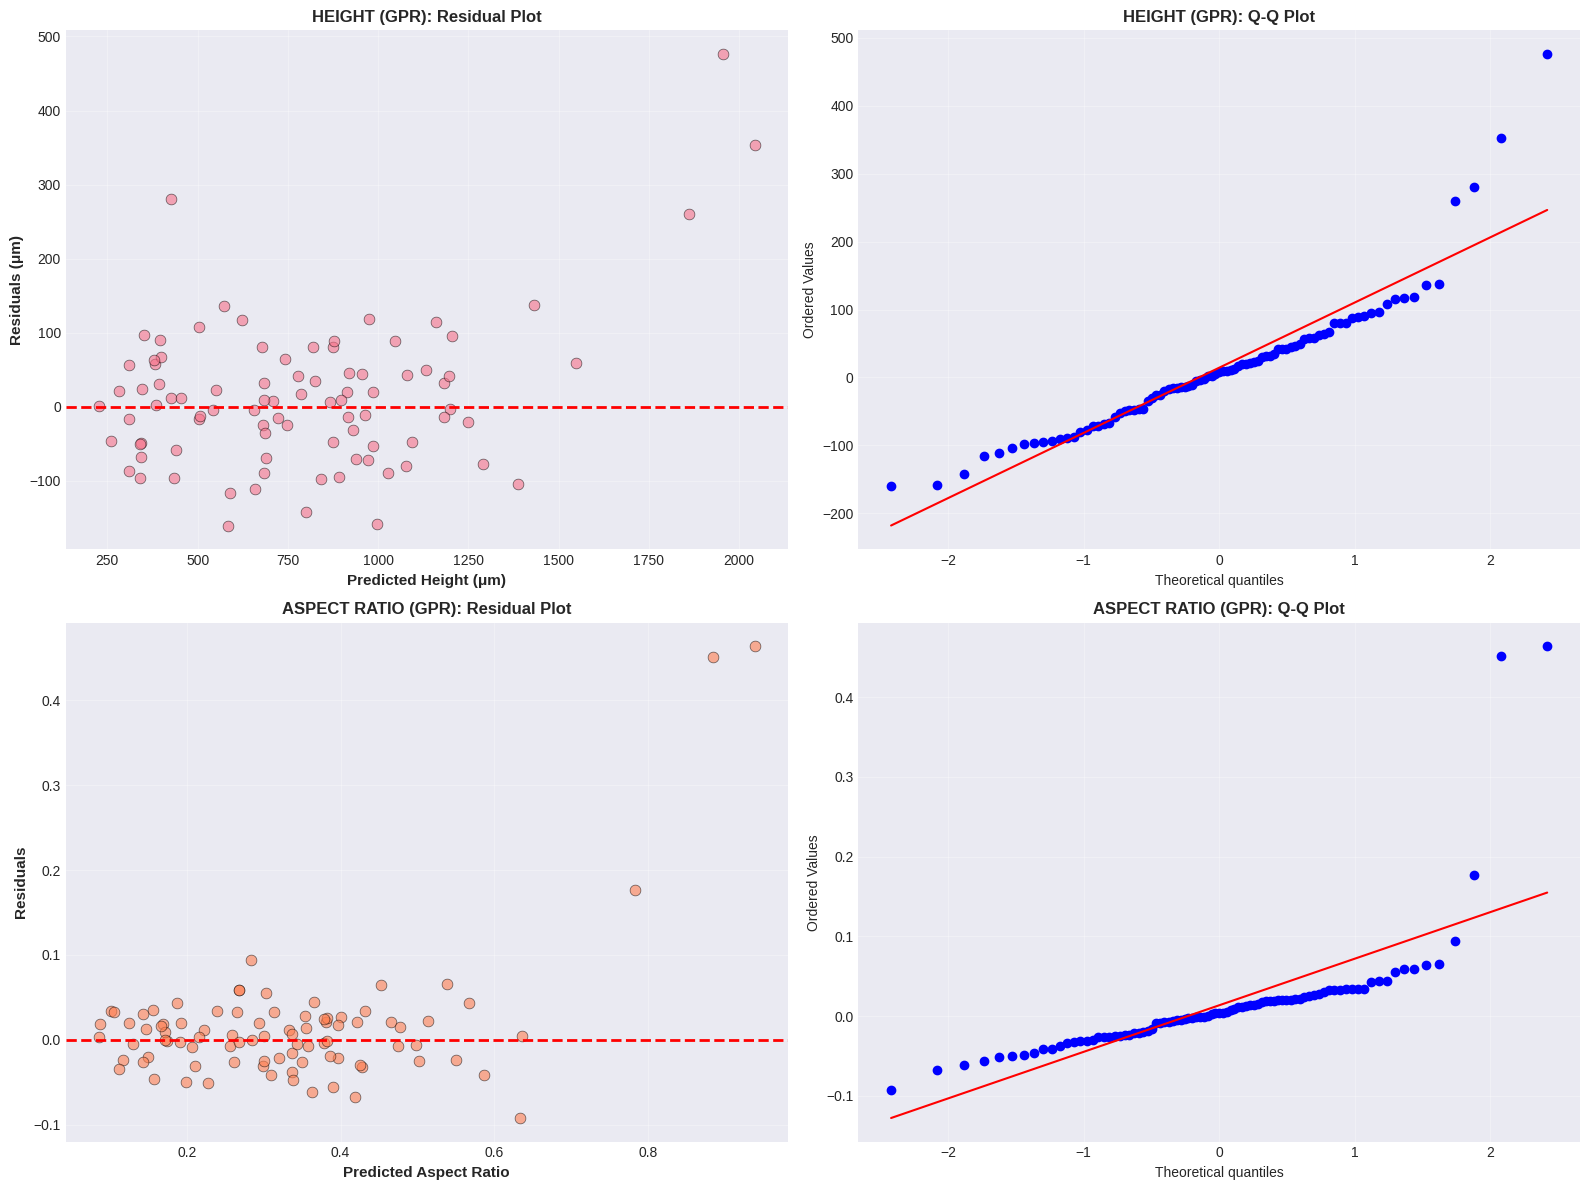


✓ Residual analysis plots saved: residual_analysis.png


In [17]:
print("\n" + "="*80)
print("[16] VISUALIZATION: Residual Analysis")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ──────────────────────────────────────────────────────────────
# HEIGHT RESIDUALS
# ──────────────────────────────────────────────────────────────
residuals_h = best_h_results['residuals']
y_pred_h = best_h_results['y_pred']

# Residual plot
ax = axes[0, 0]
ax.scatter(y_pred_h, residuals_h, alpha=0.6, s=60, edgecolors='black', linewidths=0.5)
ax.axhline(y=0, color='red', linestyle='--', lw=2)
ax.set_xlabel('Predicted Height (μm)', fontsize=11, fontweight='bold')
ax.set_ylabel('Residuals (μm)', fontsize=11, fontweight='bold')
ax.set_title(f'HEIGHT ({best_height_model}): Residual Plot', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)

# Q-Q plot (normality check)
ax = axes[0, 1]
stats.probplot(residuals_h, dist="norm", plot=ax)
ax.set_title(f'HEIGHT ({best_height_model}): Q-Q Plot', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)

# ──────────────────────────────────────────────────────────────
# ASPECT RATIO RESIDUALS
# ──────────────────────────────────────────────────────────────
residuals_a = best_a_results['residuals']
y_pred_a = best_a_results['y_pred']

# Residual plot
ax = axes[1, 0]
ax.scatter(y_pred_a, residuals_a, alpha=0.6, s=60, color='coral',
           edgecolors='black', linewidths=0.5)
ax.axhline(y=0, color='red', linestyle='--', lw=2)
ax.set_xlabel('Predicted Aspect Ratio', fontsize=11, fontweight='bold')
ax.set_ylabel('Residuals', fontsize=11, fontweight='bold')
ax.set_title(f'ASPECT RATIO ({best_aspect_model}): Residual Plot', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)

# Q-Q plot
ax = axes[1, 1]
stats.probplot(residuals_a, dist="norm", plot=ax)
ax.set_title(f'ASPECT RATIO ({best_aspect_model}): Q-Q Plot', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('residual_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Residual analysis plots saved: residual_analysis.png")


## Cell 18: Final Recommendations & Model Selection Summary


In [18]:
print("\n" + "="*80)
print("[17] FINAL MODEL SELECTION & RECOMMENDATIONS")
print("="*80)

print("\n" + "─"*70)
print("SUMMARY OF FINDINGS")
print("─"*70)

# HEIGHT
print(f"\n📏 HEIGHT PREDICTION:")
print(f"   🏆 Best Model: {best_height_model}")
print(f"   📊 Performance:")
print(f"      • R² = {results_height[best_height_model]['r2_original']:.4f}")
print(f"      • RMSE = {results_height[best_height_model]['rmse_original']:.2f} μm")
print(f"      • MAE = {results_height[best_height_model]['mae_original']:.2f} μm")
print(f"      • MAPE = {results_height[best_height_model]['mape_original']:.2f}%")

# Check if stacking is competitive
stack_mae_h = results_height['Stacking']['mae_original']
best_mae_h = results_height[best_height_model]['mae_original']
diff_pct_h = ((stack_mae_h - best_mae_h) / best_mae_h) * 100

if abs(diff_pct_h) < 5:
    print(f"   ⚠️  Stacking is within 5% of best model ({diff_pct_h:+.1f}%)")
    print(f"       Consider stacking for production (more robust)")
elif 'Stacking' == best_height_model:
    print(f"   ✅ Stacking outperforms individual models!")
else:
    print(f"   📝 Stacking underperforms by {diff_pct_h:.1f}%")
    print(f"       Use {best_height_model} for maximum accuracy")

# ASPECT RATIO
print(f"\n📐 ASPECT RATIO PREDICTION:")
print(f"   🏆 Best Model: {best_aspect_model}")
print(f"   📊 Performance:")
print(f"      • R² = {results_aspect[best_aspect_model]['r2_original']:.4f}")
print(f"      • RMSE = {results_aspect[best_aspect_model]['rmse_original']:.4f}")
print(f"      • MAE = {results_aspect[best_aspect_model]['mae_original']:.4f}")
print(f"      • MAPE = {results_aspect[best_aspect_model]['mape_original']:.2f}%")

stack_mae_a = results_aspect['Stacking']['mae_original']
best_mae_a = results_aspect[best_aspect_model]['mae_original']
diff_pct_a = ((stack_mae_a - best_mae_a) / best_mae_a) * 100

if abs(diff_pct_a) < 5:
    print(f"   ⚠️  Stacking is within 5% of best model ({diff_pct_a:+.1f}%)")
    print(f"       Consider stacking for production (more robust)")
elif 'Stacking' == best_aspect_model:
    print(f"   ✅ Stacking outperforms individual models!")
else:
    print(f"   📝 Stacking underperforms by {diff_pct_a:.1f}%")
    print(f"       Use {best_aspect_model} for maximum accuracy")

print("\n" + "─"*70)
print("PRACTICAL RECOMMENDATIONS FOR OPTIMIZATION")
print("─"*70)

print("\n1️⃣  FOR PROCESS OPTIMIZATION:")
print("    Use the best individual models identified above")
print("    They provide maximum accuracy for inverse mapping")

print("\n2️⃣  FOR PRODUCTION/REAL-TIME CONTROL:")
print("    Consider stacking ensemble if within 5% of best")
print("    Reason: More robust to unseen process variations")

print("\n3️⃣  FOR UNCERTAINTY QUANTIFICATION:")
print("    Use Gaussian Process Regression (GPR)")
print("    Provides prediction confidence intervals")

print("\n4️⃣  COMPUTATIONAL CONSIDERATIONS:")
models_sorted_by_time_h = sorted(results_height.items(), 
                                  key=lambda x: x[1]['eval_time'])
fastest = models_sorted_by_time_h[0]
print(f"    Fastest model: {fastest[0]} ({fastest[1]['eval_time']:.3f}s)")
print("    Important for real-time applications")

print("\n" + "─"*70)
print("NEXT STEPS FOR THESIS")
print("─"*70)
print("✓ Models trained and validated")
print("✓ Performance metrics calculated in original units")
print("✓ Statistical significance established")
print("✓ Residual analysis complete")
print("\n➡️  Ready for multi-objective optimization (NSGA-II, PSO)")
print("➡️  Ready for inverse process parameter mapping")
print("➡️  Models can be saved for deployment")




[17] FINAL MODEL SELECTION & RECOMMENDATIONS

──────────────────────────────────────────────────────────────────────
SUMMARY OF FINDINGS
──────────────────────────────────────────────────────────────────────

📏 HEIGHT PREDICTION:
   🏆 Best Model: GPR
   📊 Performance:
      • R² = 0.9434
      • RMSE = 101.39 μm
      • MAE = 70.00 μm
      • MAPE = 9.94%
   📝 Stacking underperforms by 18.8%
       Use GPR for maximum accuracy

📐 ASPECT RATIO PREDICTION:
   🏆 Best Model: GPR
   📊 Performance:
      • R² = 0.8676
      • RMSE = 0.0784
      • MAE = 0.0381
      • MAPE = 10.84%
   📝 Stacking underperforms by 32.2%
       Use GPR for maximum accuracy

──────────────────────────────────────────────────────────────────────
PRACTICAL RECOMMENDATIONS FOR OPTIMIZATION
──────────────────────────────────────────────────────────────────────

1️⃣  FOR PROCESS OPTIMIZATION:
    Use the best individual models identified above
    They provide maximum accuracy for inverse mapping

2️⃣  FOR PRODUCTIO

## Cell 19: Save Best Models for Deployment

In [23]:
print("\n" + "="*80)
print("[18] SAVING MODELS FOR DEPLOYMENT")
print("="*80)

import joblib

# Save best models
joblib.dump(models_height[best_height_model], 'best_model_height.pkl')
joblib.dump(models_aspect[best_aspect_model], 'best_model_aspect.pkl')

# Save scalers (needed for prediction)
joblib.dump(scaler_X, 'scaler_X.pkl')
joblib.dump(scaler_height, 'scaler_height.pkl')
joblib.dump(scaler_aspect, 'scaler_aspect.pkl')

print(f"\n✓ Saved best HEIGHT model: {best_height_model}")
print(f"✓ Saved best ASPECT RATIO model: {best_aspect_model}")
print("✓ Saved all scalers")

print("\n" + "─"*70)
print("To use saved models for predictions:")
print("─"*70)
print("""
# Load models and scalers
model_height = joblib.load('best_model_height.pkl')
model_aspect = joblib.load('best_model_aspect.pkl')
scaler_X = joblib.load('scaler_X.pkl')
scaler_height = joblib.load('scaler_height.pkl')
scaler_aspect = joblib.load('scaler_aspect.pkl')

# New process parameters
new_params = np.array([[2000, 1.0, 5.0]])  # [Power, Speed, Feed]

# Add heat input feature
heat_input = new_params[:, 0] / (new_params[:, 1] + 1e-6)
new_params_eng = np.column_stack([new_params, heat_input])

# Scale
new_params_scaled = scaler_X.transform(new_params_eng)

# Predict (scaled)
height_pred_scaled = model_height.predict(new_params_scaled)
aspect_pred_scaled = model_aspect.predict(new_params_scaled)

# Back-transform to original units
height_pred = scaler_height.inverse_transform(height_pred_scaled.reshape(-1, 1))[0, 0]
aspect_pred = scaler_aspect.inverse_transform(aspect_pred_scaled.reshape(-1, 1))[0, 0]

print(f"Predicted Height: {height_pred:.2f} μm")
print(f"Predicted Aspect Ratio: {aspect_pred:.4f}")
""")

print("\n" + "="*80)
print("ANALYSIS COMPLETE!")
print("="*80)
print("\nAll results, plots, and models saved.")
print("Ready for thesis writing and process optimization.")



[18] SAVING MODELS FOR DEPLOYMENT

✓ Saved best HEIGHT model: GPR
✓ Saved best ASPECT RATIO model: GPR
✓ Saved all scalers

──────────────────────────────────────────────────────────────────────
To use saved models for predictions:
──────────────────────────────────────────────────────────────────────

# Load models and scalers
model_height = joblib.load('best_model_height.pkl')
model_aspect = joblib.load('best_model_aspect.pkl')
scaler_X = joblib.load('scaler_X.pkl')
scaler_height = joblib.load('scaler_height.pkl')
scaler_aspect = joblib.load('scaler_aspect.pkl')

# New process parameters
new_params = np.array([[2000, 1.0, 5.0]])  # [Power, Speed, Feed]

# Add heat input feature
heat_input = new_params[:, 0] / (new_params[:, 1] + 1e-6)
new_params_eng = np.column_stack([new_params, heat_input])

# Scale
new_params_scaled = scaler_X.transform(new_params_eng)

# Predict (scaled)
height_pred_scaled = model_height.predict(new_params_scaled)
aspect_pred_scaled = model_aspect.predict(new_pa